![Banner](../images/09_12_surface_energy_balance_modeling.png)

# How Good Is the ET Map? Validation, Sensitivity and Uncertainty

An ET map looks convincing whether it is right or not. Before it is used to allocate water, it
needs evidence: comparisons with independent measurements, checks against physical limits, and an
estimate of how much each input and assumption could change the result. Flux towers are the usual
reference, but they are few, they see a footprint of a few hectares, and their own energy balance
rarely closes. This notebook builds the case for and against the METRIC results of the previous
notebooks with what is available without accounts: a water balance check over unirrigated land,
the MODIS MOD16 annual ET product, the choice of reference ET, one-at-a-time sensitivity of the
inputs, the spread over many anchor pairs, and the spread between models. It ends with an
uncertainty budget by crop and points to flux tower and OpenET comparisons for readers with free
accounts.

## Overview

### Flux towers and their limits

Eddy covariance towers measure `H` and `LE` directly every 30 minutes. They are the reference for
satellite ET, with three caveats:

1. **Energy closure.** At most sites `H + LE` adds up to only 70 to 90 % of `Rn - G`. Comparisons
   often correct the tower fluxes by distributing the residual in proportion to the Bowen ratio
   (`seb.energy_closure` measures the closure).
2. **Footprint.** A tower sees an upwind area of a few hundred metres that moves with the wind, so a
   comparison needs a footprint-weighted average of the satellite pixels.
3. **Representativeness.** Towers sit in uniform, well managed fields; satellite errors are larger
   at field edges and in mixed pixels.

The OpenET accuracy assessment (Volk et al. 2024) compared each of its models and the ensemble with
152 flux stations across the western United States. In short, the models captured croplands better
than natural vegetation, the ensemble was among the most accurate estimates for croplands, and
individual models were biased in different directions for different land covers.

### Checks without towers

- **Physical limits.** Annual ET of land that is not irrigated cannot exceed rain plus the water the
  soil can store. In a dry summer, bare fallow soil evaporates almost nothing. Exceedances measure
  bias at the dry end.
- **Independent products.** MOD16 (Penman-Monteith at 500 m) uses a different principle and
  different inputs. Agreement is not proof, but large disagreements need an explanation.
- **Sensitivity and uncertainty.** Perturbing each input and assumption, drawing many anchor pairs,
  and comparing models give the range within which the map is uncertain, even without a reference.

## Validation with GeoLattice

| Function | Purpose |
|---|---|
| `seb.compare_to_tower(pred, obs)` | bias, MAE, RMSE, R2, NSE, slope and intercept |
| `seb.energy_closure(rn, g, h, le)` | closure ratio of fluxes |
| `seb.sensitivity(func, inputs, perturbations)` | one-at-a-time sensitivity |
| `seb.monte_carlo_anchors(run, candidates, n=)` | spread over anchor pairs |
| `seb.seasonal_et`, `seb.interpolate_etrf` | seasonal totals with different reference ET |

### Learning objectives

1. Explain what flux towers measure and how energy closure and footprints affect comparisons.
2. Use a water balance to bound the bias of ET over unirrigated land.
3. Compare Landsat annual ET with MOD16 and explain the differences.
4. Quantify how the choice of reference ET changes seasonal totals.
5. Run one-at-a-time sensitivity on the METRIC inputs and see what the internal calibration absorbs.
6. Combine anchor, model and input uncertainty into a budget by crop group.

### Data

| Dataset | Content |
|---|---|
| Results of notebooks 06, 07 and 10 | `outputs/metric_20240705.nc`, `outputs/ensemble_20240705.nc`, `outputs/etrf_westside_2024.nc`, `outputs/annual_et_westside_2024.nc` (recomputed by running those notebooks if missing) |
| Reference ET of notebook 02 | `outputs/reference_et_westside_2024.csv`: ERA5, gridMET and the humidity-adjusted ERA5 ETr |
| MODIS MOD16A3GF 2024 | annual ET at 500 m, tile h08v05 |
| USDA CDL 2024, ERA5 rain | crop classes and the water balance |

### Contents

- Setup
- The water balance of unirrigated land
- MOD16 annual ET
- Which reference ET?
- Sensitivity of METRIC to its inputs
- Spread over anchor pairs
- Spread between models
- An uncertainty budget
- Flux towers and OpenET
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.surface_energy_balance as seb  # energy balance and ET models
import seb_data as sd  # chapter helper: downloads, caches and loads the scenes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

from rasterio.enums import Resampling  # resampling methods

need = ["metric_20240705.nc", "ensemble_20240705.nc", "etrf_westside_2024.nc", "annual_et_westside_2024.nc", "reference_et_westside_2024.csv"]  # earlier results
missing = [f for f in need if not (OUT / f).exists()]  # any not yet computed
assert not missing, f"run notebooks 02, 06, 07 and 10 first; missing {missing}"  # clear message
ds = sd.load_scene()  # Landsat 8, 5 July 2024
cdl = ds.cdl  # crop classes
metric = xr.open_dataset(OUT / "metric_20240705.nc").load()  # METRIC, 5 July
ens = xr.open_dataset(OUT / "ensemble_20240705.nc").load()  # five models and the ensemble, 5 July
cube = xr.open_dataset(OUT / "etrf_westside_2024.nc").load()  # ETrF and cover of 27 images
annual = xr.open_dataarray(OUT / "annual_et_westside_2024.nc").load().rio.write_crs(ds.rio.crs)  # annual ET 2024, mm
refs = pd.read_csv(OUT / "reference_et_westside_2024.csv", index_col=0, parse_dates=True)  # daily reference ET series
rain = refs["precip"]  # ERA5 rain, mm/day
GROUPS = {"Tree crops": [75, 204, 76, 211, 212, 217], "Grapes": [69], "Annual crops": [54, 2, 1, 36, 208, 24, 21, 51],
          "Fallow": [61], "Grass and shrubs": [176, 152], "Developed": [121, 122, 123, 124]}  # CDL codes per group


def by_group(**layers):  # mean of each layer per crop group
    df = xr.Dataset(layers).assign(cdl=ds.cdl).to_dataframe().select_dtypes("number").dropna()  # one row per pixel
    return pd.DataFrame({g: df[df.cdl.isin(c)].drop(columns=["cdl", "spatial_ref"], errors="ignore").mean()
                         for g, c in GROUPS.items()}).T  # group means

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_12_surface_energy_balance


## The water balance of unirrigated land

Fallow fields, rangeland and barren land are not irrigated. Over a year their ET cannot exceed the
rain by more than the change in soil water; over the dry season, bare soil can only evaporate the
rain of that season plus the water stored in its top layer (the total evaporable water, about 25 mm
for these soils, notebook 10).

In [2]:
grow = cube.etrf.sel(time=slice("2024-04-01", "2024-10-31"))  # growing season images
daily = seb.interpolate_etrf(grow, start="2024-04-01", end="2024-10-31", max_gap_days=None)  # daily ETrF, April to October
season = seb.seasonal_et(daily, refs["etr"])  # METRIC season ET with ERA5 ETr, mm
rain_season = float(rain.loc["2024-04":"2024-10"].sum())  # mm
limit = rain_season + 25.0  # rain plus the top layer's evaporable water
rows = {}  # one row per dry class
for code in (61, 176, 152, 131, 37):  # fallow, grassland, shrubland, barren, other hay (cut, then dry)
    m_ = cdl == code  # its pixels
    if int(m_.sum()) < 1000:  # too few pixels
        continue  # skip
    rows[sd.cdl_name(code)] = {"pixels": int(m_.sum()), "annual ET (mm)": float(annual.where(m_).mean()),
                               "Apr-Oct ET (mm)": float(season.where(m_).mean()), "Apr-Oct limit (mm)": limit,
                               "Apr-Oct excess (mm)": float(season.where(m_).mean()) - limit,
                               "share of pixels above the limit": float((season.where(m_) > limit).sum() / m_.sum())}  # check
print(f"rain: {rain.sum():.0f} mm in 2024, {rain_season:.0f} mm from April to October")  # the water available
pd.DataFrame(rows).T.round(2)  # table

rain: 320 mm in 2024, 38 mm from April to October


,pixels,annual ET (mm),Apr-Oct ET (mm),Apr-Oct limit (mm),Apr-Oct excess (mm),share of pixels above the limit
Fallow/idle cropland,145704.0,574.89,363.22,62.9,300.32,1.00
Grassland/pasture,49785.0,740.15,493.10,62.9,430.20,0.99
Other hay,15230.0,442.92,196.22,62.9,133.32,1.00


The check fails for every unirrigated class with enough pixels. From April to October fallow land
gets 363 mm and grassland 493 mm of METRIC ET in a season with 38 mm of rain, about 300 and 430 mm
above the physical limit, and practically every pixel exceeds it. Cut hay fields, dry after their
last cutting, exceed it by about 130 mm. Some of the excess is real: a few fields mapped as fallow were irrigated part of
the year, and weeds draw on deeper soil water after a wet spring. But the bulk is model bias at the
dry end. METRIC gives exactly zero ET only to pixels as hot as the hot anchor; a typical fallow
field a degree or two cooler gets an ETrF of 0.1 to 0.2, and the high reference ET of a Westside
summer turns that into 1.5 to 3 mm a day. The excess is an estimate of how much ET the model adds
to dry land, and it applies to every pixel that is warmer than the irrigated fields.

## MOD16 annual ET

MOD16A3GF gives annual ET at 500 m from a Penman-Monteith model driven by MODIS LAI and land cover
and by reanalysis weather. It has no thermal input and no knowledge of irrigation, so it is expected
to underestimate irrigated crops in a dry climate.

3213 cells of 500 m: Landsat mean 1106 mm, MOD16 mean 293 mm, R2 0.65


,landsat,mod16
group,,
Annual crops,1107.0,305.0
Developed,763.0,230.0
Fallow,618.0,236.0
Grapes,1546.0,348.0
Grass and shrubs,726.0,240.0
Tree crops,1406.0,312.0


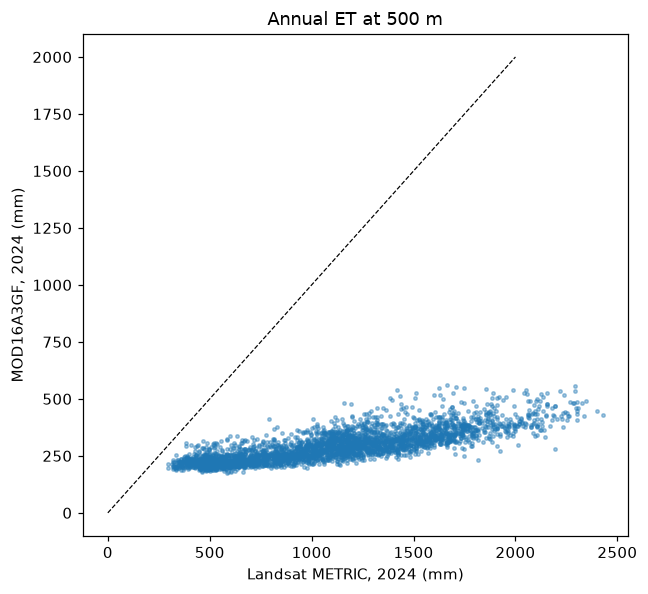

In [3]:
it = list(sd._catalog().search(collections=["modis-16A3GF-061"], bbox=sd.WESTSIDE["bbox"], datetime="2024").items())  # 2024 granules
it = [i for i in it if i.id.startswith("MOD16A3GF.A2024")][0]  # Terra, 2024
mod16 = rioxarray.open_rasterio(it.assets["ET_500m"].href, mask_and_scale=False).squeeze("band", drop=True)  # raw integers
mod16 = mod16.where(mod16 < 32700) * 0.1  # fill values for barren, urban and water removed; mm/yr
grid500 = annual.rio.reproject(annual.rio.crs, resolution=500, resampling=Resampling.average)  # Landsat annual ET, 500 m UTM grid
mod_utm = mod16.rio.reproject_match(grid500, resampling=Resampling.nearest)  # MOD16 on the same grid
crop500 = cdl.rio.write_crs(ds.rio.crs).rio.reproject_match(grid500, resampling=Resampling.mode)  # dominant crop of each cell
pair = xr.Dataset({"landsat": grid500, "mod16": mod_utm, "crop": crop500}).to_dataframe().dropna()  # matched cells
pair = pair[(pair.mod16 > 0) & (pair.landsat > 0)]  # valid pairs
st = seb.compare_to_tower(pair.mod16, pair.landsat)  # MOD16 against Landsat
print(f"{int(st.n)} cells of 500 m: Landsat mean {st.mean_obs:.0f} mm, MOD16 mean {st.mean_pred:.0f} mm, R2 {st.r2:.2f}")  # agreement
grp = pair.assign(group=pair.crop.map({c: g for g, cs in GROUPS.items() for c in cs})).dropna(subset=["group"]).groupby("group")[["landsat", "mod16"]].mean()  # by dominant group
display(grp.round(0))  # mm/yr
fig, ax = plt.subplots(figsize=(6, 5.5)); ax.scatter(pair.landsat, pair.mod16, s=5, alpha=0.4); ax.plot([0, 2000], [0, 2000], "k--", lw=0.8)  # scatter
ax.set_xlabel("Landsat METRIC, 2024 (mm)"); ax.set_ylabel("MOD16A3GF, 2024 (mm)"); ax.set_title("Annual ET at 500 m"); plt.tight_layout(); plt.show()  # labels

MOD16 follows the broad pattern of the Landsat result (R2 0.65 over 3,213 cells) but averages only
293 mm a year against 1,106 mm, and its irrigated orchards and vineyards (312 and 348 mm) get less
ET than the rain that fell (320 mm). That is not plausible for irrigated land: MOD16 constrains ET
with the dryness of the air and the MODIS land cover, and in a dry climate it cannot know that a
field is irrigated. The comparison shows that a product without thermal data is unsuitable for
irrigated agriculture; it brackets the truth from below, as the water balance brackets METRIC's dry
end from above.

## Which reference ET?

METRIC's seasonal ET is the interpolated fraction times the daily reference ET, so any bias in the
reference passes directly into the totals. The three reference series of notebook 02 give three
seasonal totals from the same fractions.

In [4]:
choices = {"ERA5 (used so far)": refs["etr"], "gridMET": refs["etr_gridmet"], "ERA5, humidity adjusted": refs["etr_humidity_adjusted"]}  # three references
tab = pd.DataFrame({name: by_group(v=seb.seasonal_et(daily, s.loc["2024-04-01":"2024-10-31"]))["v"] for name, s in choices.items()})  # season ET per group
tab.loc["reference ETr itself"] = [s.loc["2024-04-01":"2024-10-31"].sum() for s in choices.values()]  # the reference totals
tab.round(0)  # mm, April to October

,ERA5 (used so far),gridMET,"ERA5, humidity adjusted"
Tree crops,1201.0,1254.0,1058.0
Grapes,1323.0,1383.0,1165.0
Annual crops,892.0,927.0,789.0
Fallow,363.0,374.0,325.0
Grass and shrubs,498.0,515.0,444.0
Developed,653.0,678.0,579.0
reference ETr itself,1979.0,2066.0,1742.0


The fraction is the same in all three columns; only the reference changes, and every crop scales
with it. The humidity-adjusted reference lowers seasonal ET by about 12 % for every class (orchards
from 1,201 to 1,058 mm), gridMET raises it by about 4 %. For METRIC the consistent choice is to calibrate and
scale with the same reference; in this chapter that is ERA5. Correcting the reference for aridity
is the single largest lever on the orchard totals, and it does not fix the dry-land excess, which
comes from the fraction.

## Sensitivity of METRIC to its inputs

One input at a time is changed for the 5 July scene and METRIC is rerun. The summary is the mean
daily ET over cropland (orchards, grapes and annual crops).

In [5]:
p = sd.energy_inputs(ds)  # inputs of the 5 July scene
crop_mask = cdl.isin(sum((GROUPS[g] for g in ("Tree crops", "Grapes", "Annual crops")), []))  # cropland pixels


def metric_et24(lst_shift=0.0, albedo_shift=0.0, wind_factor=1.0, etr_factor=1.0, etrf_cold=1.05, hot_shift=0.0):  # METRIC with perturbed inputs
    lst = p["lst"] + lst_shift  # uniform LST error
    alb = (p["albedo"] + albedo_shift).clip(0.05, 0.6)  # albedo error
    anc = {k: dict(v) for k, v in p["anchors"].items()}  # copy of the anchors
    lst = lst + hot_shift * xr.where((np.abs(ds.x - anc["hot"]["x"]) < 1) & (np.abs(ds.y - anc["hot"]["y"]) < 1), 1, 0)  # error at the hot anchor only
    t_cold = float(lst[anc["cold"]["iy"], anc["cold"]["ix"]])  # cold anchor LST
    rl_in = seb.incoming_longwave(t_cold, seb.air_emissivity(tau_sw=float(p["tau"].median())))  # incoming longwave
    rn = seb.net_radiation(p["rs_in"], alb, rl_in, seb.outgoing_longwave(lst, p["emissivity"]), p["emissivity"])  # net radiation
    g = seb.soil_heat_flux(rn, lst, lai=p["lai"], method="metric", ndvi_=p["ndvi"])  # soil heat flux
    res = seb.run_metric(lst, rn, g, p["zom"], p["u200"] * wind_factor, p["pressure"], p["etr_inst"] * etr_factor,
                         anchors=anc, etrf_cold=etrf_cold, etr_daily=p["etr_daily"] * etr_factor)  # METRIC
    return res.et24  # mm/day


base_inputs = {"lst_shift": 0.0, "albedo_shift": 0.0, "wind_factor": 1.0, "etr_factor": 1.0, "etrf_cold": 1.05, "hot_shift": 0.0}  # unperturbed
perturb = {"lst_shift": [-2.0, 2.0], "albedo_shift": [-0.02, 0.02], "wind_factor": [-0.3, 0.3],
           "etr_factor": [-0.1, 0.1], "etrf_cold": [-0.05], "hot_shift": [-1.0, 1.0]}  # changes, added to the base values
sens = seb.sensitivity(metric_et24, base_inputs, perturb, mode="absolute", summary=lambda out: float(out.where(crop_mask).mean()))  # one at a time
sens.round(3)  # mean cropland daily ET and its change

,input,change,output,change_pct
0,base,0.00,10.486,0.000
1,lst_shift,-2.00,10.432,-0.516
2,lst_shift,2.00,10.543,0.545
3,albedo_shift,-0.02,9.807,-6.471
4,albedo_shift,0.02,10.960,4.525
5,wind_factor,-0.30,10.679,1.847
6,wind_factor,0.30,9.355,-10.786
7,etr_factor,-0.10,8.037,-23.357
8,etr_factor,0.10,12.056,14.979
9,etrf_cold,-0.05,8.961,-14.538


The table makes the strength and the weakness of internal calibration visible:

- A **uniform LST error** of 2 K changes cropland ET by about 0.5 %: the anchors shift with every
  other pixel, and `dT` is recalibrated. This is why METRIC tolerates imperfect atmospheric
  correction.
- An LST error **at the hot anchor alone** of 1 K changes cropland ET by about 2.5 %, four times as
  much as a 2 K error everywhere, because it moves the calibration line.
- An **albedo** error of 0.02 changes ET by 5 to 6 %, in a direction that may surprise: brighter
  surfaces get more ET. The cold anchor's LE is fixed by reference ET, so lower net radiation lowers
  `H` at the hot end and, through the calibration, `H` everywhere. **Wind** 30 % stronger lowers ET
  by 11 %; 30 % weaker raises it by 2 %.
- **Reference ET** is amplified: 10 % lower ETr gives 23 % lower ET, because the same ETr sets the
  cold anchor's LE and scales the day. Lowering the cold anchor's ETrF from 1.05 to 1.0 (5 %) lowers
  cropland ET by 15 %.

The anchors' assumptions and the reference ET deserve the most care.

## Spread over anchor pairs

Thirty anchor pairs drawn from the automated pools of the 5 July scene give the uncertainty that
comes from anchor choice alone.

30 successful draws; cropland mean daily ET 9.54 to 11.88 mm


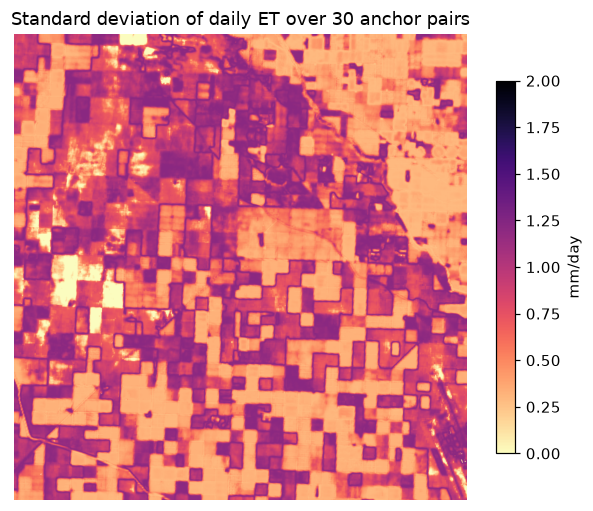

In [6]:
cand = seb.candidate_anchors(p["ndvi"], p["lst"], albedo_=p["albedo"], mask=p["mask"] & (ds.water == 0))  # anchor pools


def run(anchors):  # METRIC daily ET for one anchor pair
    return seb.run_metric(p["lst"], p["rn"], p["g"], p["zom"], p["u200"], p["pressure"], p["etr_inst"],
                          anchors=anchors, etr_daily=p["etr_daily"]).et24  # mm/day


stack, used = seb.monte_carlo_anchors(run, cand, n=30, seed=7)  # 30 anchor pairs
print(f"{int(used.ok.sum())} successful draws; cropland mean daily ET {float(stack.where(crop_mask).mean(['y', 'x']).min()):.2f} "
      f"to {float(stack.where(crop_mask).mean(['y', 'x']).max()):.2f} mm")  # range of the cropland mean
anchor_sd = stack.std("draw")  # per-pixel standard deviation, mm/day
fig, ax = plt.subplots(figsize=(7, 5.5)); im = ax.imshow(anchor_sd, cmap="magma_r", vmin=0, vmax=2)  # map
plt.colorbar(im, ax=ax, shrink=0.8, label="mm/day"); ax.set_title("Standard deviation of daily ET over 30 anchor pairs"); ax.axis("off"); plt.show()  # draw

## Spread between models

The five models of notebook 07, scaled with the same reference ET, disagree far more than anchor
pairs of one model do. Their standard deviation is a measure of structural uncertainty: the part of
the uncertainty that comes from the model's assumptions.

In [7]:
model_sd = ens.models.std("model")  # per-pixel standard deviation across the five models, mm/day
thermal_sd = ens.models.sel(model=["METRIC", "SSEBop", "S-SEBI", "Triangle"]).std("model")  # thermal models only
by_group(anchor_sd=anchor_sd, model_sd=model_sd, thermal_model_sd=thermal_sd, metric_et=metric.et24).round(2)  # mm/day

,anchor_sd,model_sd,thermal_model_sd,metric_et
Tree crops,0.64,2.93,1.55,10.73
Grapes,0.48,2.99,1.59,12.57
Annual crops,0.66,2.34,1.37,9.78
Fallow,0.85,1.04,0.95,2.72
Grass and shrubs,0.92,1.40,1.18,4.12
Developed,0.93,2.01,1.48,6.24


## An uncertainty budget

The sources combine into a budget for daily ET on 5 July, per crop group, in mm/day:

- **anchors**: standard deviation over the 30 anchor pairs;
- **models**: standard deviation across the four thermal models;
- **reference ET**: the difference between ERA5 and humidity-adjusted ETr on the day, times ETrF;
- **inputs**: half the range of the albedo and wind perturbations above, scaled to each group by its
  ET.

Adding them in quadrature assumes they are independent, which they are not exactly; the total is
an order of magnitude, not a confidence interval.

In [8]:
ref_day = float(refs.loc["2024-07-05", "etr"] - refs.loc["2024-07-05", "etr_humidity_adjusted"])  # mm, reference ET difference on the day
s_ = sens.set_index(["input", "change"])["output"]  # sensitivity outputs
base = float(sens.loc[sens.input == "base", "output"].iloc[0])  # unperturbed cropland mean
rel_inputs = np.hypot((s_[("albedo_shift", 0.02)] - s_[("albedo_shift", -0.02)]) / 2, (s_[("wind_factor", 0.3)] - s_[("wind_factor", -0.3)]) / 2) / base  # relative input uncertainty
g = by_group(et=metric.et24, etrf=metric.etrf, anchors=anchor_sd, models=thermal_sd)  # per crop group
g["reference ET"] = g.etrf * ref_day  # mm/day
g["inputs"] = g.et * rel_inputs  # mm/day
g["total (quadrature)"] = np.sqrt(g.anchors ** 2 + g.models ** 2 + g["reference ET"] ** 2 + g.inputs ** 2)  # combined
g["total / ET (%)"] = 100 * g["total (quadrature)"] / g.et  # relative
g[["et", "anchors", "models", "reference ET", "inputs", "total (quadrature)", "total / ET (%)"]].round(2)  # budget

,et,anchors,models,reference ET,inputs,total (quadrature),total / ET (%)
Tree crops,10.73,0.64,1.55,1.82,0.90,2.63,24.53
Grapes,12.57,0.48,1.59,2.13,1.05,2.90,23.08
Annual crops,9.78,0.66,1.37,1.66,0.82,2.39,24.48
Fallow,2.72,0.85,0.95,0.46,0.23,1.37,50.48
Grass and shrubs,4.12,0.92,1.18,0.70,0.34,1.69,41.02
Developed,6.24,0.93,1.48,1.06,0.52,2.11,33.80


For the crops the total is about a quarter of daily ET (23 to 25 %), with reference ET (1.7 to 2.1
mm/day) and model structure (1.4 to 1.6 mm/day) as the largest terms; anchor choice (0.5 to 0.7
mm/day over 30 pairs, whose cropland means ranged from 9.5 to 11.9 mm) is smaller. Over fallow land and rangeland the relative uncertainty is far larger (40 to 50 %), and the water balance
check showed that the bias there is larger still than this spread: the models share the same
weakness at the dry end, so their disagreement understates the error. An uncertainty budget is only
as complete as the sources it includes.

## Flux towers and OpenET

Two free resources turn these checks into a validation:

- **AmeriFlux** (ameriflux.lbl.gov, free account) distributes half-hourly fluxes for agricultural
  towers in California's Central Valley, including almond, pistachio and alfalfa sites. With a tower's
  half-hourly `LE`, `H`, `NETRAD` and `G`, `seb.energy_closure` gives its closure, and
  `seb.compare_to_tower` compares footprint-averaged METRIC daily ET with the tower's daily ET.
- **OpenET** (openetdata.org, free API key) serves the ensemble and every model for any field or
  pixel in the western United States, daily or monthly. Comparing this notebook's season totals with
  OpenET's eeMETRIC and ensemble for the same fields shows how operational calibration and reference
  ET corrections change the result.

The cell below only checks whether keys are present in the environment; it does not download
anything.

In [9]:
import os  # environment variables

for key, what in [("AMERIFLUX_USER", "AmeriFlux account"), ("OPENET_API_KEY", "OpenET API key")]:  # optional credentials
    print(f"{what}: {'found' if os.environ.get(key) else 'not set'} ({key})")  # report only

AmeriFlux account: not set (AMERIFLUX_USER)
OpenET API key: not set (OPENET_API_KEY)


## Summary and exercises

- Flux towers are the reference for satellite ET, but closure, footprints and representativeness
  must be handled; OpenET found ensembles among the most accurate estimates over croplands.
- A water balance of unirrigated land is a strong check without towers: METRIC gave fallow land
  about 300 mm and grassland about 430 mm more ET in the dry season than the rain and soil could
  supply, a bias at the dry end.
- MOD16 annual ET (293 mm on average) was below the rain even for irrigated orchards; without
  thermal data it cannot see irrigation.
- The humidity-adjusted reference lowered seasonal ET by about 12 % for every class.
- Internal calibration absorbed a 2 K uniform LST error (0.5 % change) but not errors at the hot
  anchor, in the cold anchor's ETrF (5 % gave 15 %) or in reference ET (10 % gave up to 23 %).
- The uncertainty budget for crops was about 25 % of daily ET, dominated by reference ET and model
  structure; at the dry end the water balance showed a bias larger than the models' spread.

**Exercises**

1. Repeat the water balance check with the humidity-adjusted reference ET. How much of the fallow
   excess remains?
2. Make the hot anchor pool stricter (`hot_lst_pct=95`) and rerun METRIC for 5 July. How do fallow
   ETrF and cropland ET change?
3. With an AmeriFlux account, download a Central Valley orchard tower for 2024, compute its energy
   closure and compare its July daily ET with METRIC averaged over a 300 m upwind footprint.
4. Add PT-JPL to the model spread and recompute the budget. Why does it change the budget so much?